In [ ]:
import numpy as np, math, time, random, collections
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40); pd.set_option('display.max_colwidth', 80)
plt.rcParams['figure.dpi'] = 90
SEED = 2026

## Cài đặt

### Bàn cờ và kiểm tra thắng
Bàn cờ là mảng `numpy` (hàng 0 là hàng trên cùng). Hàm `winner` dùng chỉ số các "cửa sổ" k ô liên tiếp dựng sẵn một lần cho mỗi kích thước bàn nên chạy nhanh với mọi kích thước/luật nối k.

In [14]:
import numpy as np, math, time, random

def empty_board(shape=(6, 7)):
    """0 = empty, 1 = Max (red), -1 = Min (yellow). Row 0 is the TOP row."""
    return np.full(shape, 0)

_WIN_CACHE = {}
def _windows(shape, k):
    """index arrays of every length-k line (row/col/diagonals) on a board of this shape (cached)."""
    if (shape, k) not in _WIN_CACHE:
        R, C = shape; rr, cc = [], []
        for dr, dc in ((0, 1), (1, 0), (1, 1), (1, -1)):
            for r in range(R):
                for c in range(C):
                    if 0 <= r + dr * (k - 1) < R and 0 <= c + dc * (k - 1) < C:
                        rr.append([r + dr * i for i in range(k)]); cc.append([c + dc * i for i in range(k)])
        _WIN_CACHE[(shape, k)] = (np.array(rr), np.array(cc))
    return _WIN_CACHE[(shape, k)]

def winner(board, k=4):
    """1 / -1 if that player has k in a row, 0 if nobody, 2 if BOTH do (only possible in the Mean variant)."""
    rr, cc = _windows(board.shape, k)
    s = board[rr, cc].sum(axis=1)
    w1, w2 = (s == k).any(), (s == -k).any()
    return 2 if (w1 and w2) else (1 if w1 else (-1 if w2 else 0))

def _drop(board, col, player):
    b = board.copy()
    b[np.where(b[:, col] == 0)[0].max(), col] = player   # lowest free cell of the column
    return b

### Hai trò chơi: `actions`, `result`, `utility`, `terminal`
Hai lớp có cùng giao diện nên mọi tác tử dùng được cho cả hai trò chơi. Hàm hoạt động với bàn cờ kích thước bất kỳ và luật nối k bất kỳ.

In [15]:
class Connect4:
    """Standard Connect 4 (k in a row wins). shape=(rows, cols)."""
    mean = False
    def __init__(self, shape=(6, 7), k=4): self.shape, self.k = shape, k
    def initial(self): return empty_board(self.shape)
    def actions(self, board, player=1):
        return [('drop', c) for c in range(board.shape[1]) if board[0, c] == 0]
    def result(self, board, player, a):
        return _drop(board, a[1], player)
    def utility(self, board, player=1):
        """+1 if `player` won, -1 if the opponent won, 0 draw (board full), None if not terminal."""
        w = winner(board, self.k)
        if w == 2: return 0
        if w != 0: return 1 if w == player else -1
        return 0 if not (board[0] == 0).any() else None
    def terminal(self, board): return self.utility(board, 1) is not None

class MeanConnect4(Connect4):
    """'Mean' Connect 4. On his turn a player may EITHER drop a new disc OR take a bottom-row disc of the
    OPPONENT, let everything above it fall one cell, and re-drop that disc in any column.
    Design choices (documented in the report):
      * recolor=True : the re-dropped disc becomes the mover's colour (it is 'captured').
      * both players get k-in-a-row from one move -> draw (utility 0).
      * the number of discs never changes with a 'move' action, so games can cycle -> the environment
        declares a draw after MAX_PLIES plies."""
    mean = True
    def __init__(self, shape=(6, 7), k=4, recolor=True): super().__init__(shape, k); self.recolor = recolor
    @staticmethod
    def _remove_bottom(board, c):
        b = board.copy(); b[1:, c] = board[:-1, c]; b[0, c] = 0; return b
    def actions(self, board, player=1):
        R, C = board.shape
        acts = [('drop', c) for c in range(C) if board[0, c] == 0]
        for cf in range(C):
            if board[R - 1, cf] == -player:                          # opponent disc on the bottom row
                b = self._remove_bottom(board, cf)
                acts += [('move', cf, ct) for ct in range(C) if b[0, ct] == 0]
        return acts
    def result(self, board, player, a):
        if a[0] == 'drop': return _drop(board, a[1], player)
        b = self._remove_bottom(board, a[1])
        return _drop(b, a[2], player if self.recolor else -player)

### Các tác tử
* **Random**: chọn đều trong các nước hợp lệ.
* **Alpha-Beta**: Minimax có cắt tỉa; `cutoff` + `heuristic` cho bản có giới hạn độ sâu; `ordering` chọn chiến lược sắp xếp nước đi; `time_limit` dừng tìm kiếm quá lâu.
* **Heuristic**: đếm các đường mở 3/4 và 2/4 của hai bên + thưởng nhỏ cho cột giữa.
* **Pure Monte Carlo**: N playout chia đều cho các nước đi.

In [16]:
MAX_PLIES = 200
def random_player(game):
    def agent(board, player=1): return random.choice(game.actions(board, player))
    return agent

def order_actions(game, board, acts, how='center'):
    """Move ordering. 'center': columns closest to the centre first, 'drop' before 'move' (Mean).
    'none': generation order (left to right). 'random': shuffled. 'worst': edge columns first."""
    C = board.shape[1]; mid = (C - 1) / 2
    col = lambda a: a[1] if a[0] == 'drop' else a[2]
    if how == 'center': return sorted(acts, key=lambda a: (a[0] != 'drop', abs(col(a) - mid)))
    if how == 'worst':  return sorted(acts, key=lambda a: (a[0] == 'drop', -abs(col(a) - mid)))
    if how == 'random': a2 = list(acts); random.shuffle(a2); return a2
    return acts

class SearchTimeout(Exception): pass

def alpha_beta_agent(game, cutoff=None, heuristic=None, ordering='center', time_limit=None):
    """Minimax with alpha-beta pruning. cutoff=None -> search to the end of the game.
    With a cutoff the heuristic(board, root_player) in [-1, 1] evaluates the frontier (0 if no heuristic).
    Repeated positions on the current path count as draws (needed for Mean Connect 4, whose graph has cycles).
    time_limit (s): raise SearchTimeout if exceeded. After a call: agent.last = dict(value, nodes, time)."""
    def agent(board, player=1):
        nodes = [0]; path = set(); t0 = time.perf_counter()
        def val(s, root, depth, alpha, beta, maxing):
            nodes[0] += 1
            if time_limit and time.perf_counter() - t0 > time_limit: raise SearchTimeout()
            u = game.utility(s, root)
            if u is not None: return u
            if cutoff is not None and depth >= cutoff: return heuristic(s, root) if heuristic else 0.0
            key = (s.tobytes(), maxing)
            if key in path: return 0.0
            mover = root if maxing else -root
            acts = order_actions(game, s, game.actions(s, mover), ordering)
            path.add(key)
            if maxing:
                v = -math.inf
                for a in acts:
                    v = max(v, val(game.result(s, mover, a), root, depth + 1, alpha, beta, False))
                    alpha = max(alpha, v)
                    if v >= beta: break
            else:
                v = math.inf
                for a in acts:
                    v = min(v, val(game.result(s, mover, a), root, depth + 1, alpha, beta, True))
                    beta = min(beta, v)
                    if v <= alpha: break
            path.discard(key)
            return v
        best, bv, alpha = None, -math.inf, -math.inf
        for a in order_actions(game, board, game.actions(board, player), ordering):
            v = val(game.result(board, player, a), player, 1, alpha, math.inf, False)
            if v > bv: bv, best = v, a
            alpha = max(alpha, bv)
        agent.last = dict(value=bv, nodes=nodes[0], time=time.perf_counter() - t0)
        return best
    agent.last = None
    return agent

def make_heuristic(game, w3=0.05, w2=0.01, wc=0.005):
    """Heuristic evaluation (always inside (-0.9, 0.9) so it never beats a real win/loss):
       +w3 / -w3 for every open line with k-1 own / opponent discs and one empty cell,
       +w2 / -w2 for every open line with k-2 own / opponent discs and two empty cells,
       +wc per disc in the centre column (own minus opponent)."""
    k = game.k
    def h(board, player=1):
        rr, cc = _windows(board.shape, k)
        v = board[rr, cc]
        me = (v == player).sum(axis=1); op = (v == -player).sum(axis=1)
        s = w3 * (((op == 0) & (me == k - 1)).sum() - ((me == 0) & (op == k - 1)).sum())
        s += w2 * (((op == 0) & (me == k - 2)).sum() - ((me == 0) & (op == k - 2)).sum())
        mid = board.shape[1] // 2
        s += wc * ((board[:, mid] == player).sum() - (board[:, mid] == -player).sum())
        return float(np.clip(s, -0.9, 0.9))
    return h

def playout(game, board, player, a, max_plies=150):
    """random playout after `player` plays a; utility from `player`'s point of view (0 if too long)."""
    s = game.result(board, player, a); cur = -player
    for _ in range(max_plies):
        u = game.utility(s, player)
        if u is not None: return u
        s = game.result(s, cur, random.choice(game.actions(s, cur))); cur = -cur
    return 0.0

def pmcs_agent(game, N=100):
    """Pure Monte Carlo Search: N playouts split evenly over the legal actions, best mean utility wins."""
    def agent(board, player=1):
        acts = game.actions(board, player); n = max(1, N // len(acts))
        sc = [np.mean([playout(game, board, player, a) for _ in range(n)]) for a in acts]
        agent.last = dict(zip(map(str, acts), np.round(sc, 3)))
        m = max(sc); return random.choice([a for a, s in zip(acts, sc) if s == m])
    return agent

### Môi trường thi đấu
`play` cho hai tác tử đấu N ván, trả về số thắng/hòa/thua và thời gian trung bình mỗi nước (ms).

In [17]:
def play(game, x, o, N=1, max_plies=MAX_PLIES):
    """x (Max, moves first) vs o. Returns dict(x, o, d) wins from Max's view, avg ms/move of each agent, avg length.
    Ties are broken by the agents themselves; a game longer than max_plies is a draw."""
    res = {'x': 0, 'o': 0, 'd': 0}; tx, to, lens = [], [], []
    for _ in range(N):
        b = game.initial(); p = 1; plies = 0
        while True:
            t = time.perf_counter(); a = (x if p == 1 else o)(b, p)
            (tx if p == 1 else to).append(time.perf_counter() - t)
            b = game.result(b, p, a); plies += 1
            u = game.utility(b, 1)
            if u is not None or plies >= max_plies:
                res['x' if u == 1 else 'o' if u == -1 else 'd'] += 1; break
            p = -p
        lens.append(plies)
    return dict(res=res, ms_x=1000 * np.mean(tx), ms_o=1000 * np.mean(to) if to else 0.0, avg_len=float(np.mean(lens)))

### Hiển thị

In [18]:
import matplotlib.pyplot as plt
def visualize(board, title=None, ax=None):
    """Draw the board (Randolph Rankin's idea): red = Max (1), yellow = Min (-1)."""
    R, C = board.shape
    own = ax is None
    if own: fig, ax = plt.subplots(figsize=(C * 0.6, R * 0.6))
    ax.add_patch(plt.Rectangle((-0.5, -R + 0.5), C, R, fc='royalblue'))
    for i in range(R):
        for j in range(C):
            v = board[i, j]
            ax.add_patch(plt.Circle((j, -i), 0.4, fc='white' if v == 0 else 'red' if v == 1 else 'gold'))
    ax.set_xlim(-0.5, C - 0.5); ax.set_ylim(-R + 0.5, 0.5); ax.set_aspect('equal'); ax.axis('off')
    if title: ax.set_title(title, fontsize=9)
    if own: plt.show()

In [19]:
import sys
sys.setrecursionlimit(5000)
g4, gm = Connect4(), MeanConnect4()          # bàn chuẩn 6 x 7, nối 4
NAMES = {'C4': "Connect 4 (gốc)", 'M4': "Mean Connect 4"}
GAMES = {'C4': Connect4, 'M4': MeanConnect4}

def board_from_cols(rows, cols):
    """Dựng bàn từ danh sách các cột, mỗi cột liệt kê quân từ DƯỚI lên (1 = Max, -1 = Min)."""
    b = empty_board((rows, len(cols)))
    for c, stack in enumerate(cols):
        for h, v in enumerate(stack): b[rows - 1 - h, c] = v
    return b

def versus_c4(game, agent, name, opponent=None, opp_name="Random", n=100, seed=SEED, group='C4'):
    """Tác tử đấu n ván khi đi trước (Max) và n ván khi đi sau (Min). Thắng/Hòa/Thua theo góc nhìn tác tử."""
    opponent = opponent or random_player(game); out = []
    for role in ('x', 'o'):
        random.seed(seed + (role == 'o')); np.random.seed(seed)
        if role == 'x':
            r = play(game, agent, opponent, N=n); w, l, ms = r['res']['x'], r['res']['o'], r['ms_x']
        else:
            r = play(game, opponent, agent, N=n); w, l, ms = r['res']['o'], r['res']['x'], r['ms_o']
        out.append({"Trò chơi": NAMES[group], "Tác tử": name, "Đối thủ": opp_name,
                    "Vai": "đi trước" if role == 'x' else "đi sau", "Số ván": n,
                    "Thắng": w, "Hòa": r['res']['d'], "Thua": l,
                    "Độ dài TB (nước)": round(r['avg_len'], 1), "Thời gian TB/nước (ms)": round(ms, 3)})
    return pd.DataFrame(out)

# --- kiểm tra tính đúng đắn của hai bộ luật (assert) ---
b = board_from_cols(4, [[1, 1, 1], [-1, -1], [], []])
assert Connect4((4, 4), 3).utility(b, 1) == 1 and Connect4((4, 4), 3).utility(b, -1) == -1      # dọc
b = board_from_cols(6, [[1], [-1, 1], [-1, -1, 1], [-1, -1, -1, 1]])
assert g4.utility(b, 1) == 1                                                                      # chéo
b = board_from_cols(6, [[1], [1], [1], [1]])
assert g4.utility(b, 1) == 1                                                                      # ngang
assert g4.utility(empty_board(), 1) is None and not g4.terminal(empty_board())
# Mean: chỉ được lấy quân ĐỐI THỦ ở hàng dưới cùng; quân phía trên rơi xuống 1 ô
b = board_from_cols(6, [[1, -1, 1], [-1], [], [], [], [], []])
acts = gm.actions(b, 1)
assert ('move', 1, 0) in acts and ('move', 0, 0) not in acts            # c1 có quân của Min ở đáy, c0 là quân của Max
b2 = gm.result(b, 1, ('move', 1, 3))
assert b2[5, 1] == 0 and b2[5, 3] == 1 and (b2 == 1).sum() == 3 and (b2 == -1).sum() == 1
b = board_from_cols(6, [[-1, 1, 1], [], [], []])                          # Max lấy quân đáy của Min ở c0: [1,1] rơi xuống
b3 = gm._remove_bottom(b, 0); assert list(b3[:, 0][-2:]) == [1, 1] and b3[3, 0] == 0
print("Các kiểm tra luật chơi đều đúng; số nước hợp lệ ở bàn rỗng:", len(g4.actions(empty_board())), "(Connect 4),", len(gm.actions(empty_board())), "(Mean)")

Các kiểm tra luật chơi đều đúng; số nước hợp lệ ở bàn rỗng: 7 (Connect 4), 7 (Mean)


## Task 1 – Định nghĩa bài toán tìm kiếm

| Thành phần | Connect 4 | Mean Connect 4 |
|---|---|---|
| **Trạng thái đầu** | bàn 6×7 rỗng, Max đi trước | giống nhau |
| **Actions(s)** | thả vào cột chưa đầy: ≤ 7 nước | thả vào cột chưa đầy (≤ 7) **cộng** với "lấy quân đáy của đối thủ ở cột *a* rồi đặt vào cột *b*" (≤ 7 × 7 = 49): **≤ 56 nước** |
| **Result(s, a)** | quân rơi xuống ô trống thấp nhất của cột | nước thả như cũ; nước "lấy": bỏ quân đáy ở cột *a*, các quân trên rơi 1 ô, rồi đặt quân (màu người đi) vào cột *b* |
| **Terminal(s)** | có 4 liên tiếp, hoặc bàn đầy (hòa) | như cũ; thêm: hòa khi 2 bên cùng có 4 liên tiếp, hoặc sau `MAX_PLIES` nước |
| **Utility(s)** (góc nhìn Max) | +1 Max thắng · −1 Min thắng · 0 hòa | giống nhau |

**Khác biệt cốt lõi:** trong Connect 4 mỗi nước đi làm bàn cờ *đầy thêm một quân* nên đồ thị trạng thái là **đồ thị không chu trình** (độ sâu tối đa 42). Trong Mean Connect 4 nước "lấy quân" **không làm tăng số quân**, nên có thể quay lại thế cờ cũ: đồ thị trạng thái **có chu trình** và cây trò chơi **không có độ sâu tối đa**.

### Ước lượng kích thước không gian trạng thái và cây trò chơi

In [20]:
def branching_and_length(game, n=300, seed=SEED):
    random.seed(seed); bs, L = [], []
    for _ in range(n):
        b = game.initial(); p = 1; k = 0
        while True:
            acts = game.actions(b, p); bs.append(len(acts))
            b = game.result(b, p, random.choice(acts)); k += 1
            if game.utility(b, 1) is not None or k >= MAX_PLIES: break
            p = -p
        L.append(k)
    return np.mean(bs), np.mean(L), max(L)

rows = []
for key, game in (('C4', g4), ('M4', gm)):
    bF, avgL, maxL = branching_and_length(game)
    rows.append({"Trò chơi": NAMES[key], "Nhánh TB b (chơi ngẫu nhiên)": round(bF, 2), "Độ dài ván TB d": round(avgL, 1),
                 "Độ dài ván dài nhất thấy được": maxL, "log10(b^d)  ≈ cỡ cây trung bình": round(avgL * math.log10(bF), 1)})
df_est = pd.DataFrame(rows); display(df_est)

print("Cận trên số trạng thái (không tính luật hợp lệ):")
print(f"  mỗi ô 3 giá trị                      : 3^42 = {3**42:.2e}")
print(f"  mỗi cột là chồng quân cao 0..6, mỗi quân 2 màu: (2^7 - 1)^7 = 127^7 = {127**7:.2e}   (cận trên cho CẢ hai trò chơi)")
print("Connect 4 gốc: số thế cờ hợp lệ đã được tính chính xác trong tài liệu ≈ 4.5e12 (J. Tromp), nhỏ hơn cận trên 127^7 ≈ 5.3e14 vì phải")
print("  cân bằng số quân hai bên và không chứa thế cờ đã có người thắng; Mean Connect 4 không còn ràng buộc cân bằng số quân.")
print(f"Cây Connect 4 (cận trên): 7^42 = {7.0**42:.1e} lá;  Mean: b ≤ 56 và d không bị chặn -> cây vô hạn (56^{MAX_PLIES} = 1e{MAX_PLIES*math.log10(56):.0f} nếu chặn ở {MAX_PLIES} nước)")

,Trò chơi,Nhánh TB b (chơi ngẫu nhiên),Độ dài ván TB d,Độ dài ván dài nhất thấy được,log10(b^d) ≈ cỡ cây trung bình
0,Connect 4 (gốc),6.74,21.4,42,17.8
1,Mean Connect 4,22.16,34.4,92,46.3


Cận trên số trạng thái (không tính luật hợp lệ):
  mỗi ô 3 giá trị                      : 3^42 = 1.09e+20
  mỗi cột là chồng quân cao 0..6, mỗi quân 2 màu: (2^7 - 1)^7 = 127^7 = 5.33e+14   (cận trên cho CẢ hai trò chơi)
Connect 4 gốc: số thế cờ hợp lệ đã được tính chính xác trong tài liệu ≈ 4.5e12 (J. Tromp), nhỏ hơn cận trên 127^7 ≈ 5.3e14 vì phải
  cân bằng số quân hai bên và không chứa thế cờ đã có người thắng; Mean Connect 4 không còn ràng buộc cân bằng số quân.
Cây Connect 4 (cận trên): 7^42 = 3.1e+35 lá;  Mean: b ≤ 56 và d không bị chặn -> cây vô hạn (56^200 = 1e350 nếu chặn ở 200 nước)


**Nhận xét.** Chơi ngẫu nhiên, Connect 4 có hệ số nhánh trung bình **6,74** và ván dài 21,4 nước; Mean Connect 4 có **22,16** nhánh/nước và ván dài 34,4 nước (dài nhất quan sát được: 92 nước, so với tối đa 42 của Connect 4). Cỡ cây trung bình ước lượng b^d là ~10^17,8 so với ~10^46,3. Cận trên số trạng thái là 3^42 ≈ 1,1·10^20 nếu bỏ qua trọng lực, hoặc 127^7 ≈ 5,3·10^14 khi xét các chồng quân; con số thật của Connect 4 (≈ 4,5·10^12) lấy từ tài liệu, không phải do notebook tính. Điểm khác biệt quan trọng hơn con số: **cây Mean Connect 4 không có độ sâu tối đa** vì nước "lấy quân" không làm đầy bàn.

## Task 2 – Môi trường và tác tử Random

Minh họa luật: trái là bàn mẫu của đề; giữa/phải là một nước "lấy quân" của Mean Connect 4 (Max lấy quân vàng ở đáy cột 1 và đặt vào cột 5, các quân phía trên rơi xuống).

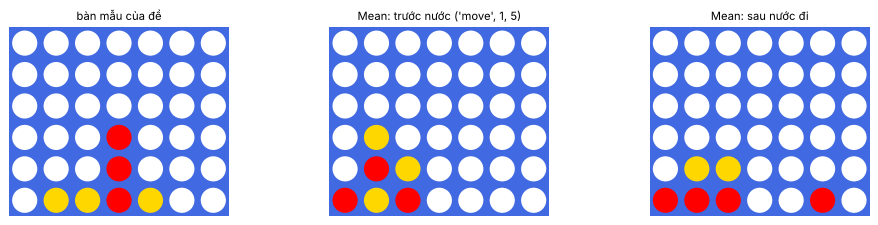

Các nước hợp lệ của Max ở bàn giữa: [('drop', 0), ('drop', 1), ('drop', 2), ('drop', 3), ('drop', 4), ('drop', 5), ('drop', 6), ('move', 1, 0), ('move', 1, 1), ('move', 1, 2)] ... 14 nước


In [21]:
sample = np.array([[0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0],
                   [0, 0, 0, 1, 0, 0, 0], [0, 0, 0, 1, 0, 0, 0], [0, -1, -1, 1, -1, 0, 0]])
mean_demo = board_from_cols(6, [[1], [-1, 1, -1], [1, -1], [], [], [], []])
fig, ax = plt.subplots(1, 3, figsize=(11, 2.6))
visualize(sample, "bàn mẫu của đề", ax[0])
visualize(mean_demo, "Mean: trước nước ('move', 1, 5)", ax[1])
visualize(gm.result(mean_demo, 1, ('move', 1, 5)), "Mean: sau nước đi", ax[2])
plt.tight_layout(); plt.show()
print("Các nước hợp lệ của Max ở bàn giữa:", gm.actions(mean_demo, 1)[:10], "...", len(gm.actions(mean_demo, 1)), "nước")

**Random vs. Random – 1000 ván trên bàn chuẩn 6×7** (Max đi trước), cho cả hai trò chơi.

In [22]:
rows = []
for key, game in (('C4', g4), ('M4', gm)):
    random.seed(SEED); np.random.seed(SEED)
    t = time.perf_counter(); r = play(game, random_player(game), random_player(game), N=1000); dt = time.perf_counter() - t
    rows.append({"Trò chơi": NAMES[key], "Số ván": 1000, "Max (đi trước) thắng": r['res']['x'], "Min thắng": r['res']['o'],
                 "Hòa": r['res']['d'], "Độ dài TB (nước)": round(r['avg_len'], 1), "Thời gian/ván (ms)": round(1000 * dt / 1000, 2)})
df_rr = pd.DataFrame(rows); display(df_rr)

,Trò chơi,Số ván,Max (đi trước) thắng,Min thắng,Hòa,Độ dài TB (nước),Thời gian/ván (ms)
0,Connect 4 (gốc),1000,547,448,5,21.1,0.32
1,Mean Connect 4,1000,501,492,7,35.0,0.78


**Nhận xét.** Connect 4: Max thắng 547, Min thắng 448, hòa 5 → người đi trước thắng hơn (54,7 % so với 44,8 %), đúng kỳ vọng. Mean Connect 4: 501 / 492 / 7 – lợi thế đi trước gần như biến mất khi cả hai chơi ngẫu nhiên, ván dài hơn (35,0 so với 21,1 nước) và mỗi ván tốn thời gian gấp ~2,4 lần (0,78 ms so với 0,32 ms). Lưu ý đây là kết quả của chơi **ngẫu nhiên**, không nói gì về lợi thế đi trước khi chơi tối ưu.

## Task 3 – Minimax với Alpha-Beta

Cài đặt ở trên (`alpha_beta_agent`): DFS đệ quy, giá trị tính theo góc nhìn của người đang chọn nước (Max = người gọi), `cutoff=None` là tìm tới cuối ván. Hai lưu ý riêng cho Mean Connect 4: (1) cần phát hiện **thế cờ lặp trên đường đi hiện tại** (tính là hòa) để không đệ quy vô hạn; (2) đồ thị có chu trình nên số nút bùng nổ rất nhanh — sẽ thấy trong các bảng thời gian bên dưới.

Bàn 6×7 quá lớn để chạy Minimax đầy đủ trong thời gian hợp lý, nên các thí nghiệm dùng **bàn nhỏ và/hoặc luật nối 3** (như đề gợi ý) rồi tăng dần kích thước.

### 3.1 Sáu bàn cờ kiểm thử thủ công (bàn 4×5, nối 3, Max đến lượt)

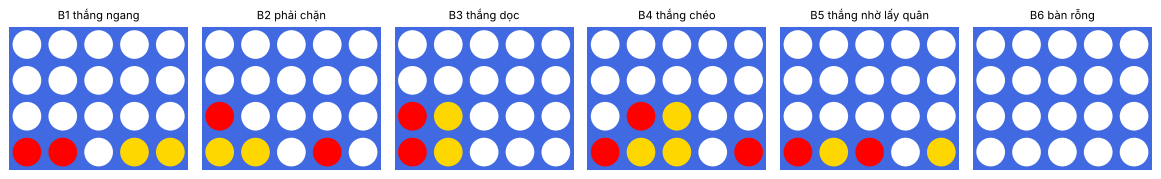

In [23]:
SH, KK = (4, 5), 3
MANUAL = {
    "B1 thắng ngang":            board_from_cols(4, [[1], [1], [], [-1], [-1]]),
    "B2 phải chặn":              board_from_cols(4, [[-1, 1], [-1], [], [1], []]),
    "B3 thắng dọc":              board_from_cols(4, [[1, 1], [-1, -1], [], [], []]),
    "B4 thắng chéo":             board_from_cols(4, [[1], [-1, 1], [-1, -1], [], [1]]),
    "B5 thắng nhờ lấy quân":     board_from_cols(4, [[1], [-1], [1], [], [-1]]),
    "B6 bàn rỗng":               empty_board(SH),
}
fig, ax = plt.subplots(1, 6, figsize=(13, 2.0))
for a, (n, b) in zip(ax, MANUAL.items()): visualize(b, n, a)
plt.tight_layout(); plt.show()

Kỳ vọng: **B1** thắng ở cột 2 · **B2** Min đang đe dọa nối hàng đáy ở cột 2 nên Max phải chặn ở cột 2 · **B3** thắng dọc ở cột 0 · **B4** thắng chéo ở cột 2 · **B5** trong Connect 4 gốc *không* có nước thắng ngay, nhưng trong Mean Connect 4 Max thắng ngay bằng cách lấy quân vàng ở đáy cột 1 và đặt lại vào cột 1 (đổi thành quân đỏ → hàng đáy đỏ-đỏ-đỏ) · **B6** bàn rỗng.

In [24]:
gk = {'C4': Connect4(SH, KK), 'M4': MeanConnect4(SH, KK)}
rows = []
for bname, b in MANUAL.items():
    for key in ('C4', 'M4'):
        g = gk[key]; h = make_heuristic(g)
        ag = alpha_beta_agent(g) if key == 'C4' else alpha_beta_agent(g, cutoff=6, heuristic=h, time_limit=60)
        mv = ag(b, 1); L = ag.last; nb = g.result(b, 1, mv)
        loses_next = any(g.utility(g.result(nb, -1, a), 1) == -1 for a in g.actions(nb, -1)) if g.utility(nb, 1) is None else False
        rows.append({"Bàn": bname, "Trò chơi": NAMES[key], "Thuật toán": "AB đầy đủ" if key == 'C4' else "AB cutoff=6",
                     "Nước đi": mv, "Thắng ngay?": "✔" if g.utility(nb, 1) == 1 else "–",
                     "Bị thua ngay sau đó?": "có" if loses_next else "không",
                     "Giá trị": round(L['value'], 3), "Số nút": L['nodes'], "Thời gian (ms)": round(1000 * L['time'], 2)})
df_manual = pd.DataFrame(rows); display(df_manual)

,Bàn,Trò chơi,Thuật toán,Nước đi,Thắng ngay?,Bị thua ngay sau đó?,Giá trị,Số nút,Thời gian (ms)
0,B1 thắng ngang,Connect 4 (gốc),AB đầy đủ,"(drop, 2)",✔,không,1.000,9,0.34
1,B1 thắng ngang,Mean Connect 4,AB cutoff=6,"(drop, 2)",✔,không,1.000,2468,72.62
2,B2 phải chặn,Connect 4 (gốc),AB đầy đủ,"(drop, 2)",–,không,1.000,913,11.34
3,B2 phải chặn,Mean Connect 4,AB cutoff=6,"(move, 0, 1)",–,không,0.040,72905,2911.70
4,B3 thắng dọc,Connect 4 (gốc),AB đầy đủ,"(drop, 1)",–,không,1.000,1398,23.25
5,B3 thắng dọc,Mean Connect 4,AB cutoff=6,"(drop, 0)",✔,không,1.000,13042,489.69
6,B4 thắng chéo,Connect 4 (gốc),AB đầy đủ,"(drop, 2)",✔,không,1.000,9,0.12
7,B4 thắng chéo,Mean Connect 4,AB cutoff=6,"(drop, 2)",✔,không,1.000,880,22.08
8,B5 thắng nhờ lấy quân,Connect 4 (gốc),AB đầy đủ,"(drop, 2)",–,không,1.000,1276,17.80
9,B5 thắng nhờ lấy quân,Mean Connect 4,AB cutoff=6,"(move, 1, 1)",✔,không,1.000,36660,1554.31


**Nhận xét.**
* **Connect 4 gốc (AB đầy đủ):** thắng ngay ở B1 và B4; ở B2 chặn đúng cột 2; ở B3 chọn cột 1 (chặn nước thắng dọc của Min) thay vì thắng ngay ở cột 0, nhưng giá trị vẫn là +1 (thắng cưỡng bức), tức là không sai nhưng không chọn đường thắng nhanh nhất; B5, B6 có giá trị +1 vì trên bàn 4×5 nối 3 người đi trước thắng được. Nguyên nhân chung: hàm giá trị không thưởng thắng sớm.
* **Mean Connect 4 (AB cutoff=6):** thắng ngay ở B1, B3, B4 và **B5 bằng nước đặc trưng ('move', 1, 1)** (lấy quân vàng ở đáy cột 1 và đặt lại thành quân đỏ → ba quân đỏ ở hàng đáy). Ở B2 nó chọn ('move', 0, 1): lấy quân đáy cột 0 của Min để phá đường 3 hàng đáy của Min, không bị thua ngay.
* Cùng một bàn nhưng chi phí chênh nhau cả bậc: B2 tốn 913 nút / 11 ms với Connect 4 nhưng 72 905 nút / 2,9 s với Mean (dù chỉ cutoff = 6), vì nhân tố nhánh lớn hơn nhiều.

### 3.2 Thời gian chọn nước đi khi tăng số cột

Bắt đầu từ bàn 4 cột rồi thêm cột. Mỗi ô là một lần tìm kiếm từ **bàn rỗng**, giới hạn thời gian mỗi lần (ghi `> giới hạn` nếu không xong). Hàng "đầy đủ" = Minimax Alpha-Beta tới cuối ván; hàng "cutoff" dùng heuristic.

In [25]:
def time_search(G, shape, k, cutoff=None, limit=30, ordering='center'):
    g = G(shape, k); h = make_heuristic(g) if cutoff else None
    ag = alpha_beta_agent(g, cutoff=cutoff, heuristic=h, ordering=ordering, time_limit=limit)
    try:
        mv = ag(g.initial(), 1); L = ag.last
        return {"Nước đi": mv, "Số nút": L['nodes'], "Thời gian (s)": round(L['time'], 3)}
    except SearchTimeout:
        return {"Nước đi": "—", "Số nút": "—", "Thời gian (s)": f"> {limit} (không xong)"}

cfgs = [("Connect 4, nối 3, đầy đủ", Connect4, 4, 3, None, 40),
        ("Connect 4, nối 4, đầy đủ", Connect4, 4, 4, None, 20),
        ("Mean C4, nối 3, đầy đủ", MeanConnect4, 4, 3, None, 10),
        ("Mean C4, nối 3, cutoff=6", MeanConnect4, 4, 3, 6, 60)]
rows = []
for label, G, rws, k, cut, lim in cfgs:
    for cols in (4, 5, 6, 7):
        if G is MeanConnect4 and cut is None and cols > 4: continue       # đã không xong ở 4 cột
        r = time_search(G, (rws, cols), k, cut, lim)
        rows.append({"Cấu hình": label, "Bàn (hàng×cột)": f"{rws}×{cols}", **r})
df_cols = pd.DataFrame(rows); display(df_cols)
r = time_search(MeanConnect4, (3, 3), 3, None, 10)
print("Mean Connect 4 trên bàn chỉ 3×3, nối 3, tìm kiếm đầy đủ:", r)

,Cấu hình,Bàn (hàng×cột),Nước đi,Số nút,Thời gian (s)
0,"Connect 4, nối 3, đầy đủ",4×4,"(drop, 1)",4225,0.053
1,"Connect 4, nối 3, đầy đủ",4×5,"(drop, 2)",15267,0.193
2,"Connect 4, nối 3, đầy đủ",4×6,"(drop, 2)",79155,1.138
3,"Connect 4, nối 3, đầy đủ",4×7,"(drop, 3)",693409,9.733
4,"Connect 4, nối 4, đầy đủ",4×4,"(drop, 1)",155967,2.14
5,"Connect 4, nối 4, đầy đủ",4×5,—,—,> 20 (không xong)
6,"Connect 4, nối 4, đầy đủ",4×6,—,—,> 20 (không xong)
7,"Connect 4, nối 4, đầy đủ",4×7,—,—,> 20 (không xong)
8,"Mean C4, nối 3, đầy đủ",4×4,—,—,> 10 (không xong)
9,"Mean C4, nối 3, cutoff=6",4×4,"(drop, 0)",11088,0.549


Mean Connect 4 trên bàn chỉ 3×3, nối 3, tìm kiếm đầy đủ: {'Nước đi': '—', 'Số nút': '—', 'Thời gian (s)': '> 10 (không xong)'}


**Nhận xét.**
* Connect 4 nối 3, đầy đủ: nút tăng ~3,7 lần (4×4 → 4×5), 5,2 lần (→ 4×6), 8,8 lần (→ 4×7): 4 225 → 693 409 nút, 0,05 s → 9,7 s. Nối 4 đã không xong trong 20 s ở bàn 4×5.
* **Mean Connect 4 không xong trong 10 s ngay cả ở bàn 3×3, nối 3** (và 4×4): không gian chỉ ~vài nghìn thế cờ nhưng nước "lấy quân" tạo vô số đường đi khác nhau giữa các thế cờ lặp lại, nên tìm kiếm theo đường đi (không ghi nhớ) bùng nổ. Phải dùng cutoff: cutoff = 6 cho 11 088 nút (0,55 s) ở 4×4 và 149 466 nút (7,4 s) ở 4×7.

### 3.3 Move ordering

**Chiến lược đơn giản:** thử các nước ở **cột giữa trước** (cột giữa tham gia nhiều đường thắng nhất nên thường là nước tốt nhất), rồi ra dần hai bên; với Mean Connect 4, các nước *thả quân* được xét trước các nước *lấy quân*. Đối chứng: `none` (từ trái sang phải), `random`, và `worst` (cố tình xét cột biên trước). Tìm kiếm tốt hơn khi nước tốt được xét sớm: nó nâng α (hoặc hạ β) sớm nên cắt được nhiều nhánh còn lại.

In [26]:
def order_row(label, G, shape, k, cutoff, limit, how, seeds=(0,)):
    g = G(shape, k); h = make_heuristic(g) if cutoff else None; res = []
    for sd in seeds:
        random.seed(SEED + sd)
        ag = alpha_beta_agent(g, cutoff=cutoff, heuristic=h, ordering=how, time_limit=limit)
        try:
            mv = ag(g.initial(), 1); res.append((mv, ag.last['nodes'], ag.last['time']))
        except SearchTimeout:
            res.append(None)
    if any(r is None for r in res):
        return {"Bài toán": label, "Thứ tự": how, "Số nút": f"> (hết {limit}s)", "Thời gian (s)": f"> {limit}", "Nước đi": "—"}
    return {"Bài toán": label, "Thứ tự": how, "Số nút": int(np.mean([r[1] for r in res])),
            "Thời gian (s)": round(float(np.mean([r[2] for r in res])), 3), "Nước đi": res[0][0]}

rows = []
for how in ('center', 'none', 'random', 'worst'):
    rows.append(order_row("Connect 4 5×5, nối 3, đầy đủ", Connect4, (5, 5), 3, None, 30, how, seeds=(0, 1, 2) if how == 'random' else (0,)))
for how in ('center', 'none', 'random', 'worst'):
    rows.append(order_row("Connect 4 6×7, cutoff=6", Connect4, (6, 7), 4, 6, 60, how, seeds=(0, 1, 2) if how == 'random' else (0,)))
for how in ('center', 'none', 'random', 'worst'):
    rows.append(order_row("Mean C4 6×7, cutoff=4", MeanConnect4, (6, 7), 4, 4, 60, how, seeds=(0, 1, 2) if how == 'random' else (0,)))
df_order = pd.DataFrame(rows); display(df_order)

,Bài toán,Thứ tự,Số nút,Thời gian (s),Nước đi
0,"Connect 4 5×5, nối 3, đầy đủ",center,47821,0.639,"(drop, 2)"
1,"Connect 4 5×5, nối 3, đầy đủ",none,2111036,28.847,"(drop, 1)"
2,"Connect 4 5×5, nối 3, đầy đủ",random,1288316,18.641,"(drop, 1)"
3,"Connect 4 5×5, nối 3, đầy đủ",worst,> (hết 30s),> 30,—
4,"Connect 4 6×7, cutoff=6",center,1933,0.075,"(drop, 3)"
5,"Connect 4 6×7, cutoff=6",none,14810,0.65,"(drop, 3)"
6,"Connect 4 6×7, cutoff=6",random,7785,0.379,"(drop, 3)"
7,"Connect 4 6×7, cutoff=6",worst,56038,2.466,"(drop, 3)"
8,"Mean C4 6×7, cutoff=4",center,2858,0.131,"(drop, 1)"
9,"Mean C4 6×7, cutoff=4",none,3430,0.158,"(drop, 0)"


**Nhận xét.**
* **Connect 4, hiệu quả rất rõ:** bàn 5×5 nối 3, "cột giữa trước" cần **47 821 nút (0,64 s)**; thứ tự trái → phải cần 2 111 036 nút (28,8 s, chậm ~44 lần); ngẫu nhiên (TB 3 seed) 1 288 316 nút (18,6 s); thứ tự xấu nhất (cột biên trước) **không xong trong 30 s**. Ở 6×7 cutoff = 6: 1 933 nút (center) so với 14 810 (none), 7 785 (random), 56 038 (worst).
* **Lý do:** Alpha-Beta chỉ cắt được nhánh khi đã gặp một nước đủ tốt để đặt cận α/β; nếu nước tốt nhất được xét đầu tiên, cận chặt ngay từ đầu và các nước còn lại bị cắt sớm. Cột giữa tham gia nhiều đường thắng nhất nên thường là nước tốt.
* **Mean Connect 4: hầu như không khác biệt** (2 858 / 3 430 / 2 096 / 3 508 nút ở 6×7 cutoff = 4; ngẫu nhiên còn ít nút hơn). Điều này cho thấy quy tắc "cột giữa + thả trước lấy quân" là một quy tắc chưa phù hợp với trò chơi này: nước tốt thường là nước "lấy quân" chứ không phải cột giữa. Cần ordering riêng cho Mean (ví dụ ưu tiên nước lấy quân tạo/chặn đường 3).

### 3.4 Những nước đầu tiên (bàn rỗng 6×7)

Bàn rỗng là **trường hợp xấu nhất** của Alpha-Beta: phải giải gần như toàn bộ cây trước khi quyết định. Cách xử lý: (a) **giới hạn độ sâu + heuristic**; (b) **sách khai cuộc** (với Connect 4 chuẩn, nước đầu tốt nhất là cột giữa — có thể tính một lần rồi tra bảng); (c) **đào sâu dần (iterative deepening)** theo ngân sách thời gian: tăng `cutoff` đến khi hết giờ và dùng kết quả của độ sâu hoàn tất gần nhất. Mình thử (a) và (c).

In [27]:
rows = []
for key in ('C4', 'M4'):
    g = GAMES[key](); h = make_heuristic(g)
    try:
        ag = alpha_beta_agent(g, time_limit=10); ag(g.initial(), 1); res = "xong"
    except SearchTimeout:
        res = "KHÔNG xong trong 10 s"
    rows.append({"Trò chơi": NAMES[key], "Cấu hình": "Minimax AB đầy đủ", "Nước đi": "—", "Số nút": "—", "Thời gian (s)": res})
    for cut in (2, 4, 6, 8):
        ag = alpha_beta_agent(g, cutoff=cut, heuristic=h, time_limit=60)
        try:
            mv = ag(g.initial(), 1); rows.append({"Trò chơi": NAMES[key], "Cấu hình": f"AB cutoff={cut}", "Nước đi": mv,
                                                   "Số nút": ag.last['nodes'], "Thời gian (s)": round(ag.last['time'], 3)})
        except SearchTimeout:
            rows.append({"Trò chơi": NAMES[key], "Cấu hình": f"AB cutoff={cut}", "Nước đi": "—", "Số nút": "—", "Thời gian (s)": "> 60"})
df_first = pd.DataFrame(rows); display(df_first)

def iterative_deepening(game, heuristic, budget=2.0):
    """Tăng cutoff 1, 2, 3, ... đến khi hết ngân sách thời gian; trả về nước đi của độ sâu hoàn tất gần nhất."""
    def agent(board, player=1):
        t0 = time.perf_counter(); best, d = None, 1
        while True:
            left = budget - (time.perf_counter() - t0)
            if left <= 0: break
            ag = alpha_beta_agent(game, cutoff=d, heuristic=heuristic, time_limit=left)
            try: best = ag(board, player)
            except SearchTimeout: break
            d += 1
        agent.depth = d - 1
        return best
    return agent

for key in ('C4', 'M4'):
    g = GAMES[key](); ag = iterative_deepening(g, make_heuristic(g), budget=2.0)
    mv = ag(g.initial(), 1); print(f"{NAMES[key]}: đào sâu dần với ngân sách 2 s -> hoàn tất độ sâu {ag.depth}, chọn {mv}")

,Trò chơi,Cấu hình,Nước đi,Số nút,Thời gian (s)
0,Connect 4 (gốc),Minimax AB đầy đủ,—,—,KHÔNG xong trong 10 s
1,Connect 4 (gốc),AB cutoff=2,"(drop, 3)",20,0.001
2,Connect 4 (gốc),AB cutoff=4,"(drop, 3)",199,0.008
3,Connect 4 (gốc),AB cutoff=6,"(drop, 3)",1933,0.104
4,Connect 4 (gốc),AB cutoff=8,"(drop, 3)",12915,0.505
5,Mean Connect 4,Minimax AB đầy đủ,—,—,KHÔNG xong trong 10 s
6,Mean Connect 4,AB cutoff=2,"(drop, 3)",27,0.001
7,Mean Connect 4,AB cutoff=4,"(drop, 1)",2858,0.187
8,Mean Connect 4,AB cutoff=6,"(drop, 1)",85694,4.17
9,Mean Connect 4,AB cutoff=8,—,—,> 60


Connect 4 (gốc): đào sâu dần với ngân sách 2 s -> hoàn tất độ sâu 8, chọn ('drop', 3)


Mean Connect 4: đào sâu dần với ngân sách 2 s -> hoàn tất độ sâu 5, chọn ('drop', 3)


**Nhận xét.** Từ bàn rỗng 6×7, Minimax Alpha-Beta đầy đủ **không xong trong 10 s** ở cả hai trò chơi. Với Connect 4, cutoff tăng 2 → 8 cho 20 → 12 915 nút (0,001 → 0,5 s), và mọi độ sâu đều chọn cột giữa (cột 3); với Mean Connect 4, cutoff 6 đã cần 85 694 nút (4,2 s), cutoff 8 không xong trong 60 s, và nước đầu thay đổi theo độ sâu (cột 3, 1, 1) – dấu hiệu heuristic chưa đáng tin ở độ nông. **Đào sâu dần** với ngân sách 2 s: Connect 4 hoàn tất độ sâu 8, Mean Connect 4 chỉ độ sâu 5, vẫn chọn cột 3. Cách xử lý thực tế: dùng cutoff/ngân sách thời gian và/hoặc **sách khai cuộc** tính trước một lần.

### 3.5 Playtime – Alpha-Beta vs. Random trên bàn nhỏ (4×5, nối 3), 100 ván mỗi vai

In [28]:
rows = []
random.seed(SEED)
ab_c4 = alpha_beta_agent(gk['C4'])
ab_m4 = alpha_beta_agent(gk['M4'], cutoff=4, heuristic=make_heuristic(gk['M4']), time_limit=30)
df_play = pd.concat([versus_c4(gk['C4'], ab_c4, "Alpha-Beta đầy đủ", group='C4'),
                     versus_c4(gk['M4'], ab_m4, "Alpha-Beta cutoff=4", group='M4')], ignore_index=True)
display(df_play)

,Trò chơi,Tác tử,Đối thủ,Vai,Số ván,Thắng,Hòa,Thua,Độ dài TB (nước),Thời gian TB/nước (ms)
0,Connect 4 (gốc),Alpha-Beta đầy đủ,Random,đi trước,100,100,0,0,6.2,70.407
1,Connect 4 (gốc),Alpha-Beta đầy đủ,Random,đi sau,100,91,0,9,7.5,92.791
2,Mean Connect 4,Alpha-Beta cutoff=4,Random,đi trước,100,100,0,0,10.2,77.045
3,Mean Connect 4,Alpha-Beta cutoff=4,Random,đi sau,100,100,0,0,10.3,83.459


**Nhận xét.** Connect 4 4×5 nối 3, Alpha-Beta đầy đủ thắng 100/100 khi đi trước và 91 thắng/9 thua khi đi sau – thua được vì với luật này người đi trước thắng được, nên một đối thủ Random may mắn có thể thắng khi ta đi sau. Mean Connect 4 (cutoff = 4) thắng 100/100 ở cả hai vai; ván dài hơn (~10 nước so với 6–7), mỗi nước ~70–93 ms.

## Task 4 – Heuristic Alpha-Beta Tree Search

### 4.1 Hàm đánh giá heuristic
Với mỗi "đường" 4 ô liên tiếp (ngang, dọc, hai chéo) mà **đối thủ chưa có quân nào**:
* có đúng 3 quân của mình + 1 ô trống → **+0,05**; có 2 quân + 2 ô trống → **+0,01**;
* (đối xứng với đối thủ → trừ điểm tương ứng);
* thưởng **+0,005** cho mỗi quân ở cột giữa (mình trừ đối thủ).

Điểm bị chặn trong (−0,9; 0,9) để một heuristic không bao giờ "đắt" hơn chiến thắng thật. Hàm này dùng chung cho cả hai trò chơi — Mean Connect 4 không có đặc trưng riêng cho nước "lấy quân" (đó là một hạn chế, sẽ bàn ở phần nhận xét).

In [29]:
h4 = make_heuristic(g4)
demo = {"bàn rỗng": empty_board(),
        "Max 3 ngang mở": board_from_cols(6, [[1], [1], [1], [], [], [], []]),
        "Max 3 ngang bị chặn 1 đầu": board_from_cols(6, [[-1], [1], [1], [1], [], [], []]),
        "Max chiếm cột giữa": board_from_cols(6, [[], [], [], [1, 1, -1], [], [], []])}
print("heuristic từ góc nhìn Max / Min:")
for n, b in demo.items(): print(f"  {n:28s} {h4(b, 1):+.3f}  /  {h4(b, -1):+.3f}")

heuristic từ góc nhìn Max / Min:
  bàn rỗng                     +0.000  /  +0.000
  Max 3 ngang mở               +0.060  /  -0.060
  Max 3 ngang bị chặn 1 đầu    +0.065  /  -0.065
  Max chiếm cột giữa           +0.005  /  -0.005


**Nhận xét.** Điểm heuristic đối xứng giữa hai bên (Max +0,06 ↔ Min −0,06) và nằm trong (−0,9; 0,9). Ba quân ngang mở ở cột 0–2 được +0,06 (một đường 3 quân: 0,05, cộng một đường 2 quân: 0,01). Khi ba quân dịch sang cột 1–3 và bị chặn ở một đầu, điểm là +0,065: vẫn có 0,05 + 0,01 từ các đường còn mở, cộng 0,005 thưởng vì có một quân ở cột giữa (cột 3). Như vậy heuristic chưa phân biệt đủ rõ giữa 'bị chặn một đầu' và 'mở hai đầu'. Hàm cũng không biết gì về nước "lấy quân" của Mean Connect 4 – một hạn chế của thiết kế.

### 4.2 Cutoff khác nhau trên sáu bàn thủ công (cùng các bàn ở 3.1)
Cột "Thắng ngay?" kiểm tra tác tử có thấy nước thắng; "Bị thua ngay?" kiểm tra tác tử có để đối thủ thắng ngay ở nước kế tiếp hay không (tức là có chặn đúng chỗ).

In [30]:
rows = []
for bname, b in MANUAL.items():
    for key in ('C4', 'M4'):
        g = gk[key]; h = make_heuristic(g)
        for cut in (2, 4, 6):
            ag = alpha_beta_agent(g, cutoff=cut, heuristic=h, time_limit=60); mv = ag(b, 1); nb = g.result(b, 1, mv)
            loses = any(g.utility(g.result(nb, -1, a), 1) == -1 for a in g.actions(nb, -1)) if g.utility(nb, 1) is None else False
            rows.append({"Bàn": bname, "Trò chơi": NAMES[key], "cutoff": cut, "Nước đi": mv,
                         "Thắng ngay?": "✔" if g.utility(nb, 1) == 1 else "–", "Bị thua ngay?": "có" if loses else "không",
                         "Số nút": ag.last['nodes']})
df_cut_manual = pd.DataFrame(rows)
piv = df_cut_manual.pivot_table(index=["Bàn", "Trò chơi"], columns="cutoff", values="Nước đi", aggfunc=lambda s: str(s.iloc[0]))
display(piv)
print("Số lần tác tử bỏ lỡ nước thắng ngay hoặc bị thua ngay trên 6 bàn × 3 cutoff:")
chk = df_cut_manual.assign(bo_lo=lambda d: ((d["Bàn"].str.contains("thắng")) & (d["Thắng ngay?"] != "✔")) | (d["Bị thua ngay?"] == "có"))
display(chk.groupby("Trò chơi")["bo_lo"].sum().rename("số lần sai"))

cutoff                                              2               4               6
Bàn                   Trò chơi                                                       
B1 thắng ngang        Connect 4 (gốc)     ('drop', 2)     ('drop', 2)     ('drop', 2)
                      Mean Connect 4      ('drop', 2)     ('drop', 2)     ('drop', 2)
B2 phải chặn          Connect 4 (gốc)     ('drop', 2)     ('drop', 2)     ('drop', 2)
                      Mean Connect 4   ('move', 0, 1)  ('move', 0, 1)  ('move', 0, 1)
B3 thắng dọc          Connect 4 (gốc)     ('drop', 0)     ('drop', 0)     ('drop', 0)
                      Mean Connect 4      ('drop', 0)     ('drop', 0)     ('drop', 0)
B4 thắng chéo         Connect 4 (gốc)     ('drop', 2)     ('drop', 2)     ('drop', 2)
                      Mean Connect 4      ('drop', 2)     ('drop', 2)     ('drop', 2)
B5 thắng nhờ lấy quân Connect 4 (gốc)     ('drop', 1)     ('drop', 2)     ('drop', 2)
                      Mean Connect 4   ('move', 1, 1)  ('move', 1, 1)  ('move', 1, 1)
B6 bàn rỗng           Connect 4 (gốc)     ('drop', 2)     ('drop', 2)     ('drop', 2)
                      Mean Connect 4      ('drop', 2)     ('drop', 2)     ('drop', 0)

Số lần tác tử bỏ lỡ nước thắng ngay hoặc bị thua ngay trên 6 bàn × 3 cutoff:


Trò chơi
Connect 4 (gốc)    3
Mean Connect 4     0
Name: số lần sai, dtype: int64

**Nhận xét.**
* Tác tử **không bỏ lỡ nước thắng hay bị thua ngay** ở cả hai trò chơi trên mọi cutoff 2, 4, 6. *Lưu ý về con số "3" của Connect 4 trong bảng trên:* đó là ba lần ở bàn B5 – bàn này có chữ "thắng" trong tên nhưng với luật Connect 4 gốc **không tồn tại nước thắng ngay**, nên đây là lỗi của phép kiểm tra chứ không phải của tác tử; số lần sai thực sự ở cả hai trò chơi là 0.
* Mean Connect 4 tìm ra nước thắng bằng cách lấy quân ở B5 ngay từ cutoff = 2 (độ sâu 2 đủ vì thắng ngay), còn Connect 4 gốc ở B5 đổi nước từ cột 1 sang cột 2 khi cutoff 2 → 4 (không có nước thắng ngay để tìm).
* Nước đi gần như ổn định theo cutoff trên các bàn đơn giản; ngoại lệ là bàn rỗng B6 ở Mean Connect 4: cutoff 2, 4 chọn cột 2 nhưng cutoff 6 chọn cột 0 → bàn rỗng là nơi heuristic quyết định chính.

### 4.3 Thời gian chọn nước đi khi tăng số cột (bàn 6 hàng, nối 4)
Đo từ một **thế cờ giữa ván cố định** (6 nước đi đầu giống nhau ở mọi kích thước), vì thế cờ giữa ván mới có đầy đủ các nước "lấy quân" của Mean Connect 4 (bàn rỗng thì chưa có quân đối thủ để lấy).

In [31]:
def mid_position(game, drops=(1, 1, 2, 2, 0, 3)):
    b = game.initial(); p = 1
    for c in drops: b = game.result(b, p, ('drop', c)); p = -p
    return b, p

rows = []
for key, cuts in (('C4', (2, 4, 6)), ('M4', (2, 3, 4))):
    for cols in (4, 5, 6, 7):
        g = GAMES[key]((6, cols), 4); b, p = mid_position(g); h = make_heuristic(g)
        for cut in cuts:
            ag = alpha_beta_agent(g, cutoff=cut, heuristic=h, time_limit=60)
            try:
                ag(b, p); rows.append({"Trò chơi": NAMES[key], "cutoff": cut, "Số cột": cols, "Số nút": ag.last['nodes'], "Thời gian (ms)": round(1000 * ag.last['time'], 1)})
            except SearchTimeout:
                rows.append({"Trò chơi": NAMES[key], "cutoff": cut, "Số cột": cols, "Số nút": "—", "Thời gian (ms)": "> 60000"})
df_hcols = pd.DataFrame(rows)
display(df_hcols.pivot_table(index=["Trò chơi", "cutoff"], columns="Số cột", values="Thời gian (ms)", aggfunc="first"))
display(df_hcols.pivot_table(index=["Trò chơi", "cutoff"], columns="Số cột", values="Số nút", aggfunc="first"))

Số cột                      4      5      6      7
Trò chơi        cutoff                            
Connect 4 (gốc) 2         1.7    1.2    1.2    0.9
                4         3.8   10.1   11.9    9.0
                6        33.7   96.6  104.6   91.8
Mean Connect 4  2         3.6    4.7    4.5    2.8
                3        27.9   26.5   29.5   35.9
                4       121.7  192.7  363.6  251.3

Số cột                     4     5     6     7
Trò chơi        cutoff                        
Connect 4 (gốc) 2         14    24    24    20
                4        108   260   287   232
                6        945  2572  2667  2455
Mean Connect 4  2         75   104    96    54
                3        657   591   667   664
                4       2740  4175  7600  4956

**Nhận xét.** Từ thế cờ giữa ván cố định: ở **cùng cutoff**, Mean Connect 4 duyệt nhiều nút hơn Connect 4 gấp ~20–30 lần (cutoff = 4: 2 740–7 600 nút so với 108–287) và chậm hơn tương ứng (cutoff = 4: 122–364 ms so với 3,8–11,9 ms). Cutoff = 3 ở Mean (26–36 ms) tương đương cutoff ≈ 5 ở Connect 4 về chi phí. Thời gian không tăng đều theo số cột (cutoff = 4 của Mean đạt đỉnh ở 6 cột: 364 ms rồi giảm xuống 251 ms ở 7 cột) vì tỉa Alpha-Beta phụ thuộc thế cờ cụ thể mỗi kích thước.

### 4.4 Playtime – hai tác tử heuristic đấu với nhau (bàn chuẩn 6×7)
Không có yếu tố ngẫu nhiên nên mỗi vai chơi **một ván**. Đối chiếu (i) cutoff khác nhau, cùng heuristic; (ii) cùng cutoff, **hai hàm heuristic khác nhau**: `tấn công` (trọng số đường 3 và 2 lớn, không thưởng cột giữa) và `vị trí` (trọng số đường nhỏ, thưởng cột giữa lớn).

In [32]:
def duel(game, f1, n1, f2, n2):
    """f1 đấu f2 một ván mỗi vai. Trả về kết quả theo góc nhìn tác tử 1 và độ dài ván."""
    out = []
    for first in (1, 2):
        x, o = (f1, f2) if first == 1 else (f2, f1)
        r = play(game, x, o, N=1); res = r['res']
        s1 = res['x'] if first == 1 else res['o']; s2 = res['o'] if first == 1 else res['x']
        out.append(("thắng" if s1 else ("thua" if s2 else "hòa")) + f" ({int(r['avg_len'])} nước)")
    return out

rows = []
for key, pairs in (('C4', [(2, 4), (4, 6)]), ('M4', [(2, 3), (3, 4)])):
    g = GAMES[key](); h = make_heuristic(g)
    for c1, c2 in pairs:
        r = duel(g, alpha_beta_agent(g, c1, h, time_limit=30), f"cutoff {c1}", alpha_beta_agent(g, c2, h, time_limit=30), f"cutoff {c2}")
        rows.append({"Trò chơi": NAMES[key], "Cặp đấu": f"cutoff={c1} vs cutoff={c2} (cùng heuristic)", "tác tử 1 đi trước": r[0], "tác tử 1 đi sau": r[1]})
    hA, hB = make_heuristic(g, 0.10, 0.03, 0.0), make_heuristic(g, 0.02, 0.01, 0.05); c = 4 if key == 'C4' else 3
    r = duel(g, alpha_beta_agent(g, c, hA, time_limit=30), "tấn công", alpha_beta_agent(g, c, hB, time_limit=30), "vị trí")
    rows.append({"Trò chơi": NAMES[key], "Cặp đấu": f"heuristic 'tấn công' vs 'vị trí' (cùng cutoff={c})", "tác tử 1 đi trước": r[0], "tác tử 1 đi sau": r[1]})
df_hh = pd.DataFrame(rows); display(df_hh)

,Trò chơi,Cặp đấu,tác tử 1 đi trước,tác tử 1 đi sau
0,Connect 4 (gốc),cutoff=2 vs cutoff=4 (cùng heuristic),thua (38 nước),thua (33 nước)
1,Connect 4 (gốc),cutoff=4 vs cutoff=6 (cùng heuristic),thua (42 nước),thắng (42 nước)
2,Connect 4 (gốc),heuristic 'tấn công' vs 'vị trí' (cùng cutoff=4),thắng (33 nước),thua (37 nước)
3,Mean Connect 4,cutoff=2 vs cutoff=3 (cùng heuristic),hòa (200 nước),hòa (200 nước)
4,Mean Connect 4,cutoff=3 vs cutoff=4 (cùng heuristic),hòa (200 nước),hòa (200 nước)
5,Mean Connect 4,heuristic 'tấn công' vs 'vị trí' (cùng cutoff=3),thua (16 nước),thua (17 nước)


**Nhận xét.**
* **Connect 4:** cutoff 2 thua cutoff 4 cả hai vai; cutoff 4 thua cutoff 6 khi đi trước nhưng thắng khi đi sau – nhìn xa hơn thường mạnh hơn nhưng không tuyệt đối. Giữa hai heuristic cùng cutoff 4, mỗi bên thắng khi đi trước (ván 33 và 37 nước): hai hàm đánh giá này gần như ngang nhau, kết quả do lợi thế đi trước.
* **Mean Connect 4:** các cặp cutoff (2 vs 3, 3 vs 4) đều **hòa 200 nước ở cả hai vai**: hai tác tử xác định lặp lại các nước "lấy quân" qua lại mà không bên nào phá được – quy tắc hòa sau 200 nước của môi trường có tác dụng. Đây là hậu quả của việc chơi xác định + đồ thị có chu trình. Heuristic 'vị trí' thắng 'tấn công' cả hai vai chỉ sau 16–17 nước, nghĩa là bản 'tấn công' (không thưởng cột giữa) bị khai thác nhanh – có thể do nó quá chú trọng đường 3/2 mà không bảo vệ cột giữa.

### 4.5 Heuristic Alpha-Beta vs. Random (bàn 6×7)
Cutoff nhỏ chạy 100 ván mỗi vai; cutoff lớn (đắt) chạy ít ván hơn, ghi rõ ở cột "Số ván".

In [33]:
plan = [('C4', 2, 100), ('C4', 4, 100), ('C4', 6, 30), ('M4', 2, 100), ('M4', 3, 100), ('M4', 4, 20)]
parts = []
for key, cut, n in plan:
    g = GAMES[key](); ag = alpha_beta_agent(g, cutoff=cut, heuristic=make_heuristic(g), time_limit=60)
    parts.append(versus_c4(g, ag, f"Heuristic AB (cutoff={cut})", n=n, group=key))
df_hrand = pd.concat(parts, ignore_index=True); display(df_hrand)

,Trò chơi,Tác tử,Đối thủ,Vai,Số ván,Thắng,Hòa,Thua,Độ dài TB (nước),Thời gian TB/nước (ms)
0,Connect 4 (gốc),Heuristic AB (cutoff=2),Random,đi trước,100,100,0,0,10.6,1.195
1,Connect 4 (gốc),Heuristic AB (cutoff=2),Random,đi sau,100,100,0,0,13.6,1.169
2,Connect 4 (gốc),Heuristic AB (cutoff=4),Random,đi trước,100,100,0,0,12.1,12.122
3,Connect 4 (gốc),Heuristic AB (cutoff=4),Random,đi sau,100,100,0,0,14.4,14.306
4,Connect 4 (gốc),Heuristic AB (cutoff=6),Random,đi trước,30,30,0,0,14.0,130.704
5,Connect 4 (gốc),Heuristic AB (cutoff=6),Random,đi sau,30,30,0,0,15.7,145.200
6,Mean Connect 4,Heuristic AB (cutoff=2),Random,đi trước,100,100,0,0,20.0,6.511
7,Mean Connect 4,Heuristic AB (cutoff=2),Random,đi sau,100,100,0,0,20.7,7.028
8,Mean Connect 4,Heuristic AB (cutoff=3),Random,đi trước,100,100,0,0,15.8,81.414
9,Mean Connect 4,Heuristic AB (cutoff=3),Random,đi sau,100,100,0,0,13.9,81.000


**Nhận xét.** Trước Random, mọi cấu hình heuristic đều thắng toàn bộ ván ở cả hai trò chơi (Connect 4: 100/100 ở cutoff 2 và 4, 30/30 ở cutoff 6; Mean: 100/100 ở cutoff 2 và 3, 20/20 ở cutoff 4), nên tỷ lệ thắng không phân biệt được chất lượng. Khác biệt nằm ở **chi phí và độ dài ván**: Connect 4 mất 1,2 → 12 → 131 ms/nước cho cutoff 2 → 4 → 6; Mean mất 6,5 → 81 → 499 ms cho cutoff 2 → 3 → 4; ván Mean dài hơn (~14–22 nước so với ~11–16 của Connect 4) vì tác tử không có heuristic về nước lấy quân nên không "đóng ván" nhanh.

## Mở rộng – Pure Monte Carlo Search và nước đi đầu tiên tốt nhất

### 5.1 PMCS trên các bàn thủ công (4×5, nối 3)
Mỗi bàn chạy PMCS 10 lần với N = 100 và N = 1000; ghi nước hay gặp nhất, tần suất của nó và % lần chọn nước "hợp lý" (nước thắng ngay ở B1, B3, B4, B5; nước chặn ở B2).

In [34]:
good = {"B1 thắng ngang": {('drop', 2)}, "B2 phải chặn": {('drop', 2)}, "B3 thắng dọc": {('drop', 0)},
        "B4 thắng chéo": {('drop', 2)}, "B5 thắng nhờ lấy quân": {('move', 1, 1)}}
rows = []
for bname, b in MANUAL.items():
    for key in ('C4', 'M4'):
        g = gk[key]
        for N in (100, 1000):
            random.seed(SEED); ag = pmcs_agent(g, N=N); picks = []; t = time.perf_counter()
            for _ in range(10): picks.append(ag(b, 1))
            ms = 1000 * (time.perf_counter() - t) / 10
            modal, f = collections.Counter(picks).most_common(1)[0]
            ok = "" if bname not in good or (key == 'C4' and bname == "B5 thắng nhờ lấy quân") else f"{100 * np.mean([p in good[bname] for p in picks]):.0f}%"
            rows.append({"Bàn": bname, "Trò chơi": NAMES[key], "N": N, "Nước hay gặp": modal, "Tần suất": f"{10 * f}%",
                         "% chọn nước hợp lý": ok, "ms/nước": round(ms, 1)})
df_pm_manual = pd.DataFrame(rows)
display(df_pm_manual.pivot_table(index=["Bàn", "Trò chơi"], columns="N", values=["Nước hay gặp", "Tần suất", "% chọn nước hợp lý"], aggfunc="first"))

% chọn nước hợp lý        Nước hay gặp               Tần suất      
N                                                   100   1000          100           1000     100   1000
Bàn                   Trò chơi                                                                           
B1 thắng ngang        Connect 4 (gốc)               100%  100%     (drop, 2)     (drop, 2)     100%  100%
                      Mean Connect 4                 30%   30%  (move, 4, 2)  (move, 4, 2)      50%   40%
B2 phải chặn          Connect 4 (gốc)                90%  100%     (drop, 2)     (drop, 2)      90%  100%
                      Mean Connect 4                  0%    0%  (move, 1, 0)  (move, 1, 2)      20%   30%
B3 thắng dọc          Connect 4 (gốc)               100%  100%     (drop, 0)     (drop, 0)     100%  100%
                      Mean Connect 4                 60%   70%     (drop, 0)     (drop, 0)      60%   70%
B4 thắng chéo         Connect 4 (gốc)               100%  100%     (drop, 2)     (drop, 2)     100%  100%
                      Mean Connect 4                 80%  100%     (drop, 2)     (drop, 2)      80%  100%
B5 thắng nhờ lấy quân Connect 4 (gốc)                              (drop, 0)     (drop, 2)      50%   80%
                      Mean Connect 4                 50%  100%  (move, 1, 1)  (move, 1, 1)      50%  100%
B6 bàn rỗng           Connect 4 (gốc)                              (drop, 2)     (drop, 2)     100%  100%
                      Mean Connect 4                               (drop, 2)     (drop, 2)      40%   50%

**Nhận xét.** Trên Connect 4, PMCS chọn đúng ở B1–B4 với 90–100 % (cả N = 100 và 1000). Trên Mean Connect 4 kém hơn nhiều: B1 chỉ 30 %, B2 **0 %** (không chặn được đe dọa), B3 60–70 %; chỉ khi N=1000 mới đạt 100 % ở B4, B5. Giải thích hợp lý: ngân sách N chia cho nhiều nước hơn (nhiều nước "lấy quân"), và các ván mô phỏng ngẫu nhiên của Mean dài và hỗn loạn nên tín hiệu "thắng ngay" bị pha loãng. Đây là suy luận từ số liệu, chưa kiểm chứng riêng.

### 5.2 PMCS vs. Random (6×7)

In [35]:
plan = [('C4', 100, 100), ('C4', 500, 30), ('M4', 100, 100), ('M4', 500, 30)]
parts = []
for key, N, n in plan:
    g = GAMES[key](); parts.append(versus_c4(g, pmcs_agent(g, N=N), f"Pure Monte Carlo (N={N})", n=n, group=key))
df_pmrand = pd.concat(parts, ignore_index=True); display(df_pmrand)

,Trò chơi,Tác tử,Đối thủ,Vai,Số ván,Thắng,Hòa,Thua,Độ dài TB (nước),Thời gian TB/nước (ms)
0,Connect 4 (gốc),Pure Monte Carlo (N=100),Random,đi trước,100,99,0,1,12.4,22.574
1,Connect 4 (gốc),Pure Monte Carlo (N=100),Random,đi sau,100,96,0,4,14.0,20.507
2,Connect 4 (gốc),Pure Monte Carlo (N=500),Random,đi trước,30,30,0,0,9.9,116.407
3,Connect 4 (gốc),Pure Monte Carlo (N=500),Random,đi sau,30,30,0,0,12.1,109.105
4,Mean Connect 4,Pure Monte Carlo (N=100),Random,đi trước,100,96,0,4,27.2,52.049
5,Mean Connect 4,Pure Monte Carlo (N=100),Random,đi sau,100,93,0,7,27.8,49.684
6,Mean Connect 4,Pure Monte Carlo (N=500),Random,đi trước,30,30,0,0,21.0,299.057
7,Mean Connect 4,Pure Monte Carlo (N=500),Random,đi sau,30,30,0,0,20.2,294.392


**Nhận xét.** Trước Random trên bàn 6×7, PMCS N=100 thắng 99 ván (đi trước) và 96 (đi sau) ở Connect 4, 96 và 93 ở Mean Connect 4; N=500 thắng toàn bộ 30 ván mỗi vai ở cả hai trò chơi. Chi phí/nước: Connect 4 ~22 ms (N=100) và ~110 ms (N=500); Mean ~50 ms và ~295 ms. Ván Mean cũng dài hơn (~27 nước so với ~13).

### 5.3 Nước đi đầu tiên tốt nhất trên bàn chuẩn 6×7
Cách làm: với **mỗi cột** chạy 2 000 playout ngẫu nhiên và lấy lợi ích trung bình của Max (tác tử `pmcs_agent` với N = 2000 × 7). Đối chiếu với nước đi đầu tiên của Alpha-Beta cutoff = 6 (mục 3.4).

,Trò chơi,cột 0,cột 1,cột 2,cột 3,cột 4,cột 5,cột 6,Nước tốt nhất (PMCS)
0,Connect 4 (gốc),0.048,0.074,0.158,0.273,0.162,0.100,0.031,3
1,Mean Connect 4,-0.009,0.004,0.004,0.004,0.017,0.009,-0.029,4


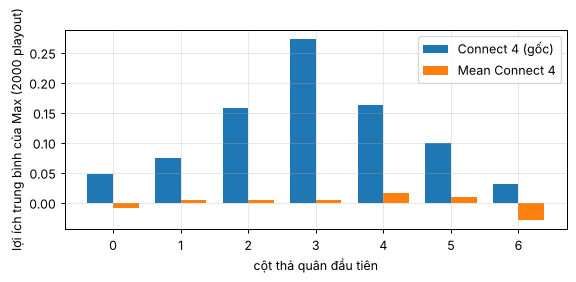

In [36]:
rows, scores = [], {}
for key in ('C4', 'M4'):
    g = GAMES[key](); random.seed(SEED)
    cols = [c for c in range(7)]; sc = []
    for c in cols:
        sc.append(float(np.mean([playout(g, g.initial(), 1, ('drop', c)) for _ in range(2000)])))
    scores[key] = sc
    rows.append({"Trò chơi": NAMES[key], **{f"cột {c}": round(v, 3) for c, v in enumerate(sc)}, "Nước tốt nhất (PMCS)": int(np.argmax(sc))})
df_best = pd.DataFrame(rows); display(df_best)
fig, ax = plt.subplots(figsize=(6.5, 3))
w = .38
ax.bar(np.arange(7) - w / 2, scores['C4'], w, label=NAMES['C4']); ax.bar(np.arange(7) + w / 2, scores['M4'], w, label=NAMES['M4'])
ax.set_xlabel("cột thả quân đầu tiên"); ax.set_ylabel("lợi ích trung bình của Max (2000 playout)"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

**Nhận xét.**
* **Connect 4:** cột giữa (cột 3) có lợi ích trung bình cao nhất rõ rệt (0,273), cách xa cột 2 và 4 (0,158 và 0,162) và các cột biên (0,031–0,048); trùng với nước đi đầu của Alpha-Beta cutoff = 2…8 (cột 3).
* **Mean Connect 4:** các giá trị chỉ nằm trong khoảng −0,029…0,017. Với 2 000 playout, sai số chuẩn của một trung bình ~ 0,022, nên **sự khác nhau giữa các cột không có ý nghĩa thống kê** – PMCS với ngân sách này không chọn được nước đầu tiên tốt nhất, khớp với việc Random vs Random ở Mean gần như cân bằng (501 / 492). Để xác định cần nhiều playout hơn hoặc chính sách playout tốt hơn.

## So sánh hành vi giữa Connect 4 và Mean Connect 4
Tập hợp các số liệu chính ở trên để đối chiếu hai trò chơi.

In [37]:
def pick(df, **kw):
    d = df
    for k, v in kw.items(): d = d[d[k] == v]
    return d

rows = []
for key in ('C4', 'M4'):
    nm = NAMES[key]; r_rr = pick(df_rr, **{"Trò chơi": nm}).iloc[0]; r_e = pick(df_est, **{"Trò chơi": nm}).iloc[0]
    hc = pick(df_hrand, **{"Trò chơi": nm, "Tác tử": "Heuristic AB (cutoff=2)", "Vai": "đi trước"}).iloc[0]
    pc = pick(df_pmrand, **{"Trò chơi": nm, "Tác tử": "Pure Monte Carlo (N=100)", "Vai": "đi trước"}).iloc[0]
    hc4 = pick(df_hrand, **{"Trò chơi": nm, "Tác tử": "Heuristic AB (cutoff=4)", "Vai": "đi trước"})
    rows.append({"Trò chơi": nm, "Nhánh TB (ngẫu nhiên)": r_e["Nhánh TB b (chơi ngẫu nhiên)"], "Độ dài ván Random-Random": r_rr["Độ dài TB (nước)"],
                 "Random-Random: Max thắng / Min thắng / hòa /1000": f"{r_rr['Max (đi trước) thắng']} / {r_rr['Min thắng']} / {r_rr['Hòa']}",
                 "Heuristic cutoff=2 vs Random (đi trước): T/H/B": f"{hc['Thắng']} / {hc['Hòa']} / {hc['Thua']}  ({hc['Thời gian TB/nước (ms)']} ms)",
                 "Heuristic cutoff=4 vs Random (đi trước): T/H/B": (f"{hc4.iloc[0]['Thắng']} / {hc4.iloc[0]['Hòa']} / {hc4.iloc[0]['Thua']}  ({hc4.iloc[0]['Thời gian TB/nước (ms)']} ms)" if len(hc4) else "—"),
                 "PMCS N=100 vs Random (đi trước): T/H/B": f"{pc['Thắng']} / {pc['Hòa']} / {pc['Thua']}  ({pc['Thời gian TB/nước (ms)']} ms)"})
df_cmp = pd.DataFrame(rows).set_index("Trò chơi").T; display(df_cmp)

Trò chơi,Connect 4 (gốc),Mean Connect 4
Nhánh TB (ngẫu nhiên),6.74,22.16
Độ dài ván Random-Random,21.1,35.0
Random-Random: Max thắng / Min thắng / hòa /1000,547 / 448 / 5,501 / 492 / 7
Heuristic cutoff=2 vs Random (đi trước): T/H/B,100 / 0 / 0 (1.195 ms),100 / 0 / 0 (6.511 ms)
Heuristic cutoff=4 vs Random (đi trước): T/H/B,100 / 0 / 0 (12.122 ms),20 / 0 / 0 (498.796 ms)
PMCS N=100 vs Random (đi trước): T/H/B,99 / 0 / 1 (22.574 ms),96 / 0 / 4 (52.049 ms)


**Tóm tắt so sánh hành vi Connect 4 và Mean Connect 4.**
1. **Hệ số nhánh và chi phí:** Mean có nhánh ~3,3 lần lớn hơn (22,2 so với 6,7) và đồ thị có chu trình → Minimax đầy đủ không khả thi ngay cả trên bàn 3×3, cần cutoff; cùng cutoff thì chậm hơn 20–30 lần.
2. **Lợi thế đi trước:** rõ ở Connect 4 (54,7 % vs 44,8 % khi chơi ngẫu nhiên), gần như mất ở Mean (50,1 % vs 49,2 %).
3. **Ván chơi:** Mean dài hơn (35 so với 21 nước ngẫu nhiên) và hai tác tử xác định dễ rơi vào **vòng lặp hòa**.
4. **Tác tử:** cùng tác tử (heuristic, PMCS) đều thắng Random ở cả hai trò chơi, nhưng ở Mean các tác tử kém tin cậy hơn trên các thế tactical (PMCS 0 % ở B2) và move ordering "cột giữa" không còn hiệu quả.